In [ ]:
# 检查论文Allen Key数据集打包时是否乱序

import zarr
import numpy as np
import cv2
import os

zarr_path = "/mnt/storage/mmm/recur_UniT/allen_key_gelsight/replay_buffer.zarr"
root = zarr.open(zarr_path, mode="r")
print(root.tree())

images = root["data"]["tactile_image"]
episode_ends = root["meta"]["episode_ends"]

print("\nimage shape:", images.shape)
print("image dtype:", images.dtype)

print("\nepisode number:", len(episode_ends))
print("episode ends:", episode_ends[:])

os.makedirs("check_frames", exist_ok=True)
# 先查看第一个 episode
start_idx = 0
end_idx = int(episode_ends[0])

print("first episode:")
print("start:", start_idx)
print("end:", end_idx)
print("length:", end_idx - start_idx)

# 从这个 episode 中连续取前10帧
for i in range(start_idx, min(start_idx + 10, end_idx)):
    image = np.array(images[i])
    # 如果保存的是 RGB，cv2.imwrite 需要转成 BGR
    if image.shape[-1] == 3:
        image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    cv2.imwrite(
        f"check_frames/frame_{i:04d}.png",
        image
    )

print("saved!")

# 通过简单的指标来判断
for i in range(start_idx, min(start_idx + 9, end_idx - 1)):

    img1 = np.array(images[i]).astype(np.float32)
    img2 = np.array(images[i + 1]).astype(np.float32)

    diff = np.mean(np.abs(img1 - img2))

    print(
        f"{i} -> {i+1}, mean abs diff = {diff:.4f}"
    )

/
 ├── data
 │   └── tactile_image (10854, 240, 320, 3) uint8
 └── meta
     └── episode_ends (5,) int64

image shape: (10854, 240, 320, 3)
image dtype: uint8

episode number: 5
episode ends: [ 1350  2672  5056  5224 10854]
first episode:
start: 0
end: 1350
length: 1350
saved!
0 -> 1, mean abs diff = 1.3879
1 -> 2, mean abs diff = 0.0000
2 -> 3, mean abs diff = 1.3874
3 -> 4, mean abs diff = 1.3838
4 -> 5, mean abs diff = 1.3855
5 -> 6, mean abs diff = 1.3867
6 -> 7, mean abs diff = 1.3859
7 -> 8, mean abs diff = 1.3880
8 -> 9, mean abs diff = 1.3849


Number of episodes: 38

Data keys:
['3Dpose', 'tactile_image']

Data shapes:
3Dpose: shape=(11340, 4), dtype=float32
tactile_image: shape=(11340, 240, 320, 3), dtype=uint8

Episode 10: start=3987, end=4687, length=700
Global frame indices: [4087 4088 4089 4090 4091 4092 4093 4094]


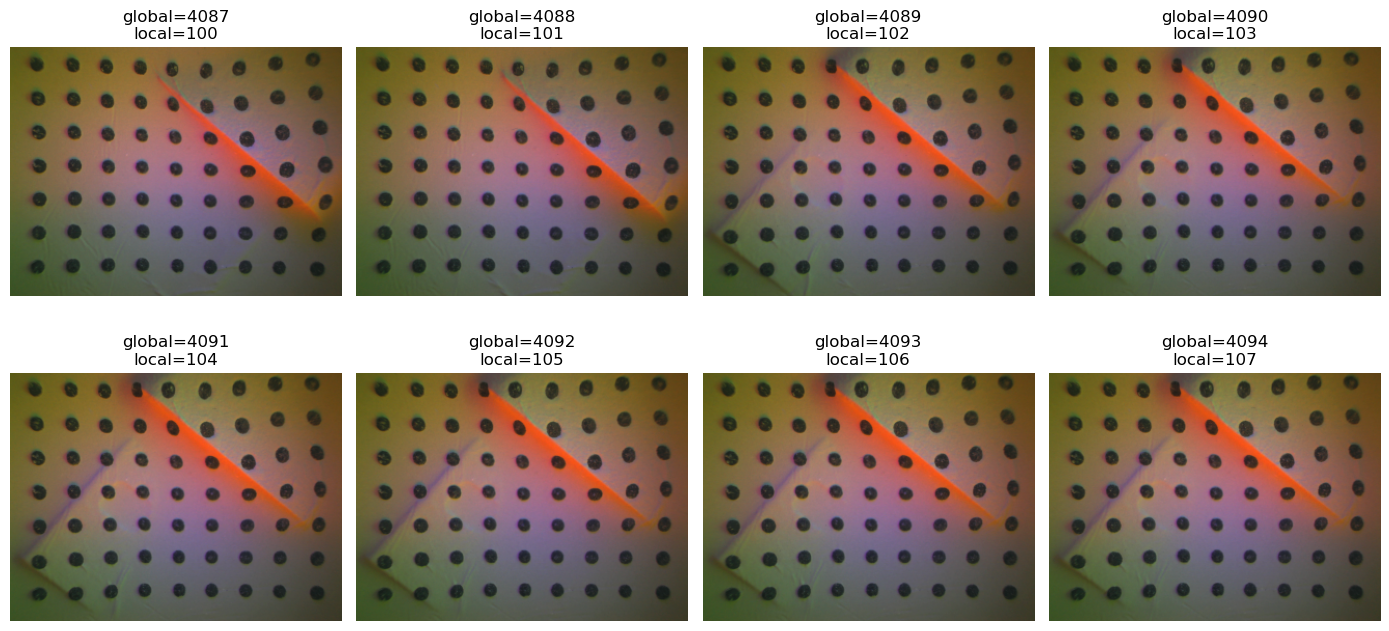


========== Adjacent image difference ==========
4087 -> 4088: mean abs diff = 1.869514
4088 -> 4089: mean abs diff = 6.808138
4089 -> 4090: mean abs diff = 3.472205
4090 -> 4091: mean abs diff = 2.274952
4091 -> 4092: mean abs diff = 1.995590
4092 -> 4093: mean abs diff = 2.308533
4093 -> 4094: mean abs diff = 2.409952

========== Adjacent quaternion difference ==========
4087 -> 4088: rotation change = 6.784179 deg
4088 -> 4089: rotation change = 3.327965 deg
4089 -> 4090: rotation change = 1.597424 deg
4090 -> 4091: rotation change = 1.022807 deg
4091 -> 4092: rotation change = 0.649418 deg
4092 -> 4093: rotation change = 0.234154 deg
4093 -> 4094: rotation change = 3.050930 deg

========== Quaternion values ==========
4087: [-0.71014506 -0.2351161  -0.6164696   0.24572305], norm=1.000000
4088: [-0.69987726 -0.29219055 -0.60532826  0.24160773], norm=1.000000
4089: [-0.6948922  -0.31851953 -0.59552747  0.24701656], norm=1.000000
4090: [-0.6939576  -0.30657804 -0.6026423   0.24749754]

In [4]:
# 检查论文3D pose数据集打包时是否乱序

import numpy as np
import cv2
import matplotlib.pyplot as plt
from UniT.dataset.tactile_perception_dataset import _get_replay_buffer
import numpy as np
import matplotlib.pyplot as plt

dataset_path = "/mnt/storage/mmm/recur_UniT/3D_pose_gelsight"
replay_buffer = _get_replay_buffer(dataset_path)
print("Number of episodes:", replay_buffer.n_episodes)

# 看有哪些 key
print("\nData keys:")
print(list(replay_buffer.keys()))
print("\nData shapes:")
for key in replay_buffer.keys():
    arr = replay_buffer[key]
    print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")


images = replay_buffer["tactile_image"]
poses = replay_buffer["3Dpose"]
episode_ends = np.asarray(replay_buffer.episode_ends)
episode_starts = np.concatenate([[0], episode_ends[:-1]])


episode_id = 10
start = episode_starts[episode_id]
end = episode_ends[episode_id]
print(f"\nEpisode {episode_id}: start={start}, end={end}, length={end-start}")

# 取该 episode 连续 8 帧
local_start = 100
global_start = start + local_start
num_frames = 8
indices = np.arange(global_start, global_start + num_frames)
print("Global frame indices:", indices)

# 看连续图像
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx in zip(axes.flat, indices):
    img = images[idx]
    ax.imshow(img)
    ax.set_title(
        f"global={idx}\n"
        f"local={idx-start}"
    )
    ax.axis("off")
plt.tight_layout()
plt.savefig(
    "3Dpose_continuous_frames.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# 相邻图像的平均绝对差
print("\n========== Adjacent image difference ==========")
for i in range(len(indices)-1):
    idx1 = indices[i]
    idx2 = indices[i+1]

    img1 = images[idx1].astype(np.float32)
    img2 = images[idx2].astype(np.float32)
    diff = np.abs(img1 - img2).mean()

    print(
        f"{idx1} -> {idx2}: "
        f"mean abs diff = {diff:.6f}"
    )

# 检查 quaternion 是否连续
def quaternion_angle_deg(q1, q2):
    q1 = np.asarray(q1, dtype=np.float64)
    q2 = np.asarray(q2, dtype=np.float64)
    # 先归一化
    q1 = q1 / np.linalg.norm(q1)
    q2 = q2 / np.linalg.norm(q2)

    # q 和 -q 表示同一个旋转，所以取绝对值
    dot = np.abs(np.dot(q1, q2))
    # 避免浮点误差导致 arccos 越界
    dot = np.clip(dot, -1.0, 1.0)
    angle = 2.0 * np.arccos(dot)

    return np.degrees(angle)

print("\n========== Adjacent quaternion difference ==========")
for i in range(len(indices)-1):
    idx1 = indices[i]
    idx2 = indices[i+1]

    q1 = poses[idx1]
    q2 = poses[idx2]

    angle = quaternion_angle_deg(q1, q2)

    print(
        f"{idx1} -> {idx2}: "
        f"rotation change = {angle:.6f} deg"
    )

# 顺便打印 quaternion 本身
print("\n========== Quaternion values ==========")
for idx in indices:
    print(
        f"{idx}: {poses[idx]}, "
        f"norm={np.linalg.norm(poses[idx]):.6f}"
    )


In [2]:
# test_temporal_dataset 看经过处理成四帧的数据是否真的是[B, T, H, W, C]格式

from UniT.dataset.tactile_representation_dataset import TactileRepresentationDataset
from torch.utils.data import DataLoader

dataset = TactileRepresentationDataset(
    shape_meta={
        'obs': {
            'tactile_image': {
                'shape': [3, 240, 320],
                'type': 'rgb'
            }
        }
    },

    dataset_path='/mnt/storage/mmm/recur_UniT/allen_key_gelsight',

    horizon=4,
    pad_before=0,
    pad_after=0,

    seed=42,
    val_ratio=0,
    max_train_episodes=None,

    resized_image_shape=(128, 160)
)

print("dataset length:", len(dataset))

sample = dataset[0]

print("single sample:")
print(type(sample['image']))
print(sample['image'].shape) # [T, H, W, C]

loader = DataLoader(
    dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0
)

batch = next(iter(loader))

print("batch:")
print(type(batch['image']))
print(batch['image'].shape) # [B, T, H, W, C]

dataset length: 10839
single sample:
<class 'numpy.ndarray'>
(4, 128, 160, 3)
batch:
<class 'torch.Tensor'>
torch.Size([2, 4, 128, 160, 3])


In [1]:
from omegaconf import OmegaConf
import torch
from UniT.dataset.tactile_representation_dataset import TactileRepresentationDataset
from UniT.dataset.representation_wrapper import RepresentationWrapper
from UniT.taming.models.vqgan import TemporalVQModel

cfg = OmegaConf.load("UniT/config/vqvae_representation_key.yaml")
dataset = TactileRepresentationDataset( **cfg.dataset)
wrapper = RepresentationWrapper(dataset, cfg)

loader = wrapper.train_dataloader()
batch = next(iter(loader))
model = TemporalVQModel(**cfg.model)
model.eval()

# 检查输入
x = model.get_input(batch, "image")
print("after get_input:", x.shape)

# 检查 Encoder
B, T, C, H, W = x.shape
x_flat = x.reshape(B*T, C, H, W)
print("before encoder:", x_flat.shape)

# with torch.no_grad():
#     h_flat = model.encoder(x_flat)
# print("after encoder:", h_flat.shape)
# h_seq = h_flat.reshape(B, T, *h_flat.shape[1:])
# print("after restore T:", h_seq.shape)

# 完整 forward
# with torch.no_grad():
#     xrec, qloss = model(x)
# print("reconstruction:", xrec.shape)
# print("target:", x[:, -1].shape)

with torch.no_grad():
    h_flat = model.encoder(x_flat)
    h_seq = h_flat.reshape(B, T, *h_flat.shape[1:])
    print("before temporal:", h_seq.shape)

    h_temporal = model.temporal_fusion(h_seq)

    print("after temporal:",h_temporal.shape)

    xrec, qloss = model(x)
    print("reconstruction:",xrec.shape)
    print("target:",x[:, -1].shape)

/mnt/nvme0n1/home/mmm/miniconda3/envs/unitenv_no_t3/lib/python3.9/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/mnt/nvme0n1/home/mmm/miniconda3/envs/unitenv_no_t3/lib/python3.9/site-packages/llvmlite/binding/ffi.py:175: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


Working with z of shape (1, 3, 16, 16) = 768 dimensions.


/mnt/nvme0n1/home/mmm/miniconda3/envs/unitenv_no_t3/lib/python3.9/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and will be removed in 0.15, please use 'weights' instead.
  warnings.warn(
/mnt/nvme0n1/home/mmm/miniconda3/envs/unitenv_no_t3/lib/python3.9/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and will be removed in 0.15. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


loaded pretrained LPIPS loss from taming/modules/autoencoder/lpips/vgg.pth
VQLPIPSWithDiscriminator running with hinge loss.
after get_input: torch.Size([2, 4, 3, 128, 160])
before encoder: torch.Size([8, 3, 128, 160])
before temporal: torch.Size([2, 4, 3, 16, 20])
after temporal: torch.Size([2, 3, 16, 20])
reconstruction: torch.Size([2, 3, 128, 160])
target: torch.Size([2, 3, 128, 160])


In [1]:
# check_disc_update 检查判别器是否真的进行参数更新

import torch

baseline_ckpt_path = "/mnt/storage/mmm/recur_UniT/2024-08-01T15-09-47vq/checkpoints/checkpoint-epoch=342.ckpt"
temporal_ckpt_path = "/mnt/nvme0n1/home/mmm/projects/UniT/representation_models/2026-09-18T09-33-05temporal_vq/checkpoints/checkpoint-epoch=29.ckpt"


def load_state_dict(path):
    ckpt = torch.load(path, map_location="cpu")

    # Lightning checkpoint 一般是这种结构
    if isinstance(ckpt, dict) and "state_dict" in ckpt:
        return ckpt["state_dict"]

    # 如果本身就是 state_dict
    return ckpt

baseline_sd = load_state_dict(baseline_ckpt_path)
temporal_sd = load_state_dict(temporal_ckpt_path)


# 找 discriminator 参数
disc_keys = [
    k for k in baseline_sd.keys()
    if "discriminator" in k and k in temporal_sd
]

print("=" * 80)
print("找到的 discriminator 参数数量:", len(disc_keys))
print("=" * 80)

if len(disc_keys) == 0:
    print("没有找到 discriminator 参数！")
    print("\nbaseline 中包含 discriminator 字样的 key：")

    for k in baseline_sd.keys():
        if "disc" in k.lower():
            print(k)

    raise SystemExit


# 比较训练前后参数
changed_count = 0
unchanged_count = 0
results = []
for k in disc_keys:
    w_before = baseline_sd[k]
    w_after = temporal_sd[k]

    # 某些 state_dict 中可能包含非 Tensor 内容
    if not torch.is_tensor(w_before):
        continue

    if w_before.shape != w_after.shape:
        print(f"[Shape 不一致] {k}")
        print(w_before.shape, w_after.shape)
        continue

    # 转成 float，方便比较
    before = w_before.detach().float()
    after = w_after.detach().float()
    diff = (after - before).abs()

    mean_diff = diff.mean().item()
    max_diff = diff.max().item()
    changed = max_diff > 1e-8

    if changed:
        changed_count += 1
    else:
        unchanged_count += 1

    results.append(
        (k, mean_diff, max_diff, changed)
    )


print("\n训练前后 discriminator 参数变化：\n")
for k, mean_diff, max_diff, changed in results:
    status = "CHANGED" if changed else "UNCHANGED"
    print(
        f"{status:10s} | "
        f"mean diff = {mean_diff:.6e} | "
        f"max diff = {max_diff:.6e} | "
        f"{k}"
    )
print("\n" + "=" * 80)

print("发生变化的参数数量 :", changed_count)
print("没有变化的参数数量 :", unchanged_count)
print("总参数 Tensor 数量 :", changed_count + unchanged_count)
print("=" * 80)

/mnt/nvme0n1/home/mmm/miniconda3/envs/unitenv_no_t3_pl17/lib/python3.9/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/mnt/nvme0n1/home/mmm/miniconda3/envs/unitenv_no_t3_pl17/lib/python3.9/site-packages/pytorch_lightning/utilities/imports.py:22: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


找到的 discriminator 参数数量: 22

训练前后 discriminator 参数变化：

CHANGED    | mean diff = 8.754503e-04 | max diff = 5.802767e-03 | loss.discriminator.main.0.weight
CHANGED    | mean diff = 5.124004e-05 | max diff = 9.651966e-04 | loss.discriminator.main.0.bias
CHANGED    | mean diff = 9.670731e-05 | max diff = 2.085449e-03 | loss.discriminator.main.2.weight
CHANGED    | mean diff = 4.053162e-05 | max diff = 1.482964e-04 | loss.discriminator.main.3.weight
CHANGED    | mean diff = 4.149109e-06 | max diff = 1.238286e-05 | loss.discriminator.main.3.bias
CHANGED    | mean diff = 9.445999e-03 | max diff = 5.102181e-02 | loss.discriminator.main.3.running_mean
CHANGED    | mean diff = 7.043526e-04 | max diff = 3.164530e-03 | loss.discriminator.main.3.running_var
CHANGED    | mean diff = 6.102000e+04 | max diff = 6.102000e+04 | loss.discriminator.main.3.num_batches_tracked
CHANGED    | mean diff = 2.084481e-05 | max diff = 8.095382e-04 | loss.discriminator.main.5.weight
CHANGED    | mean diff = 6.566406e-

In [2]:
import torch

path = "/mnt/nvme0n1/home/mmm/projects/UniT/representation_models/2026-09-18T09-33-05temporal_vq/checkpoints/checkpoint-epoch=29.ckpt"

ckpt = torch.load(path, map_location="cpu")

print(ckpt.keys())

print("epoch:", ckpt.get("epoch"))
print("global_step:", ckpt.get("global_step"))

print(
    "optimizer states:",
    len(ckpt.get("optimizer_states", []))
)

dict_keys(['epoch', 'global_step', 'pytorch-lightning_version', 'state_dict', 'loops', 'callbacks', 'optimizer_states', 'lr_schedulers'])
epoch: 29
global_step: 20340
optimizer states: 2
